# Neural networks for point-source detection

This notebook uses simulated images of blurred point sources. It compares source-count probabilities from prior-based and network-based source selection with an independent numerical integration. Candidate source positions are supplied in advance. A separate experiment compares source-flux uncertainties from mixture and diffusion networks.

In [1]:
import json
from contextlib import redirect_stdout
from io import StringIO
from uuid import uuid4

from pcat.demo import (
    display_example_visuals,
    load_example_namespace,
    run_example_script,
)
from tdpy.verbosity import print

run_id = f"notebook_smoke_{uuid4().hex[:12]}"

## Short image run

The default benchmark entry point now runs point-source images. The short setting uses few training examples and iterations to check execution. The paper results use the longer recorded runs, not this short run. Each fresh run identifier preserves previous images, samples, and trained networks.

In [2]:
with redirect_stdout(StringIO()):
    run_example_script(
        "neural_proposal_efficiency/point_source_detection.py",
        "--smoke",
        "--run-id",
        run_id,
    )

## Recorded image results

The saved output contains the simulated images, source-count probabilities from numerical integration, and the actual count samples. A short run checks execution rather than posterior accuracy. The full runs reported in the paper use two chains of 20,000 iterations per image.

In [3]:
with redirect_stdout(StringIO()):
    benchmark = load_example_namespace(
        "neural_proposal_efficiency/point_source_detection.py"
    )
result_path = benchmark["Path"](benchmark["__file__"]).parent / "data" / f"{run_id}_point_sources.json"
print(f"Reading from {result_path.name}...")
with result_path.open(encoding="utf-8") as stream:
    summary = json.load(stream)["cases"]
summary

[{'reference_count_probability': [0.908075390657309,
   0.0891617756461345,
   0.002762833696554525],
  'runs': [{'method': 'prior',
    'chain': 0,
    'seed': 273,
    'seconds': 0.002316624999366468,
    'count_probability': [0.0, 0.7666666666666667, 0.23333333333333334],
    'acceptance_counts': {'within': 23, 'birth': 4, 'death': 3}},
   {'method': 'prior',
    'chain': 1,
    'seed': 274,
    'seconds': 0.0019165000012435485,
    'count_probability': [0.9, 0.1, 0.0],
    'acceptance_counts': {'within': 24, 'birth': 2, 'death': 2}},
   {'method': 'prior',
    'combined_count_probability': [0.45,
     0.43333333333333335,
     0.11666666666666667],
    'total_variation_from_reference': 0.45807539065730996},
   {'method': 'neural',
    'chain': 0,
    'seed': 273,
    'seconds': 0.012260374998732004,
    'count_probability': [1.0, 0.0, 0.0],
    'acceptance_counts': {'within': 24, 'birth': 0, 'death': 0}},
   {'method': 'neural',
    'chain': 1,
    'seed': 274,
    'seconds': 0.012

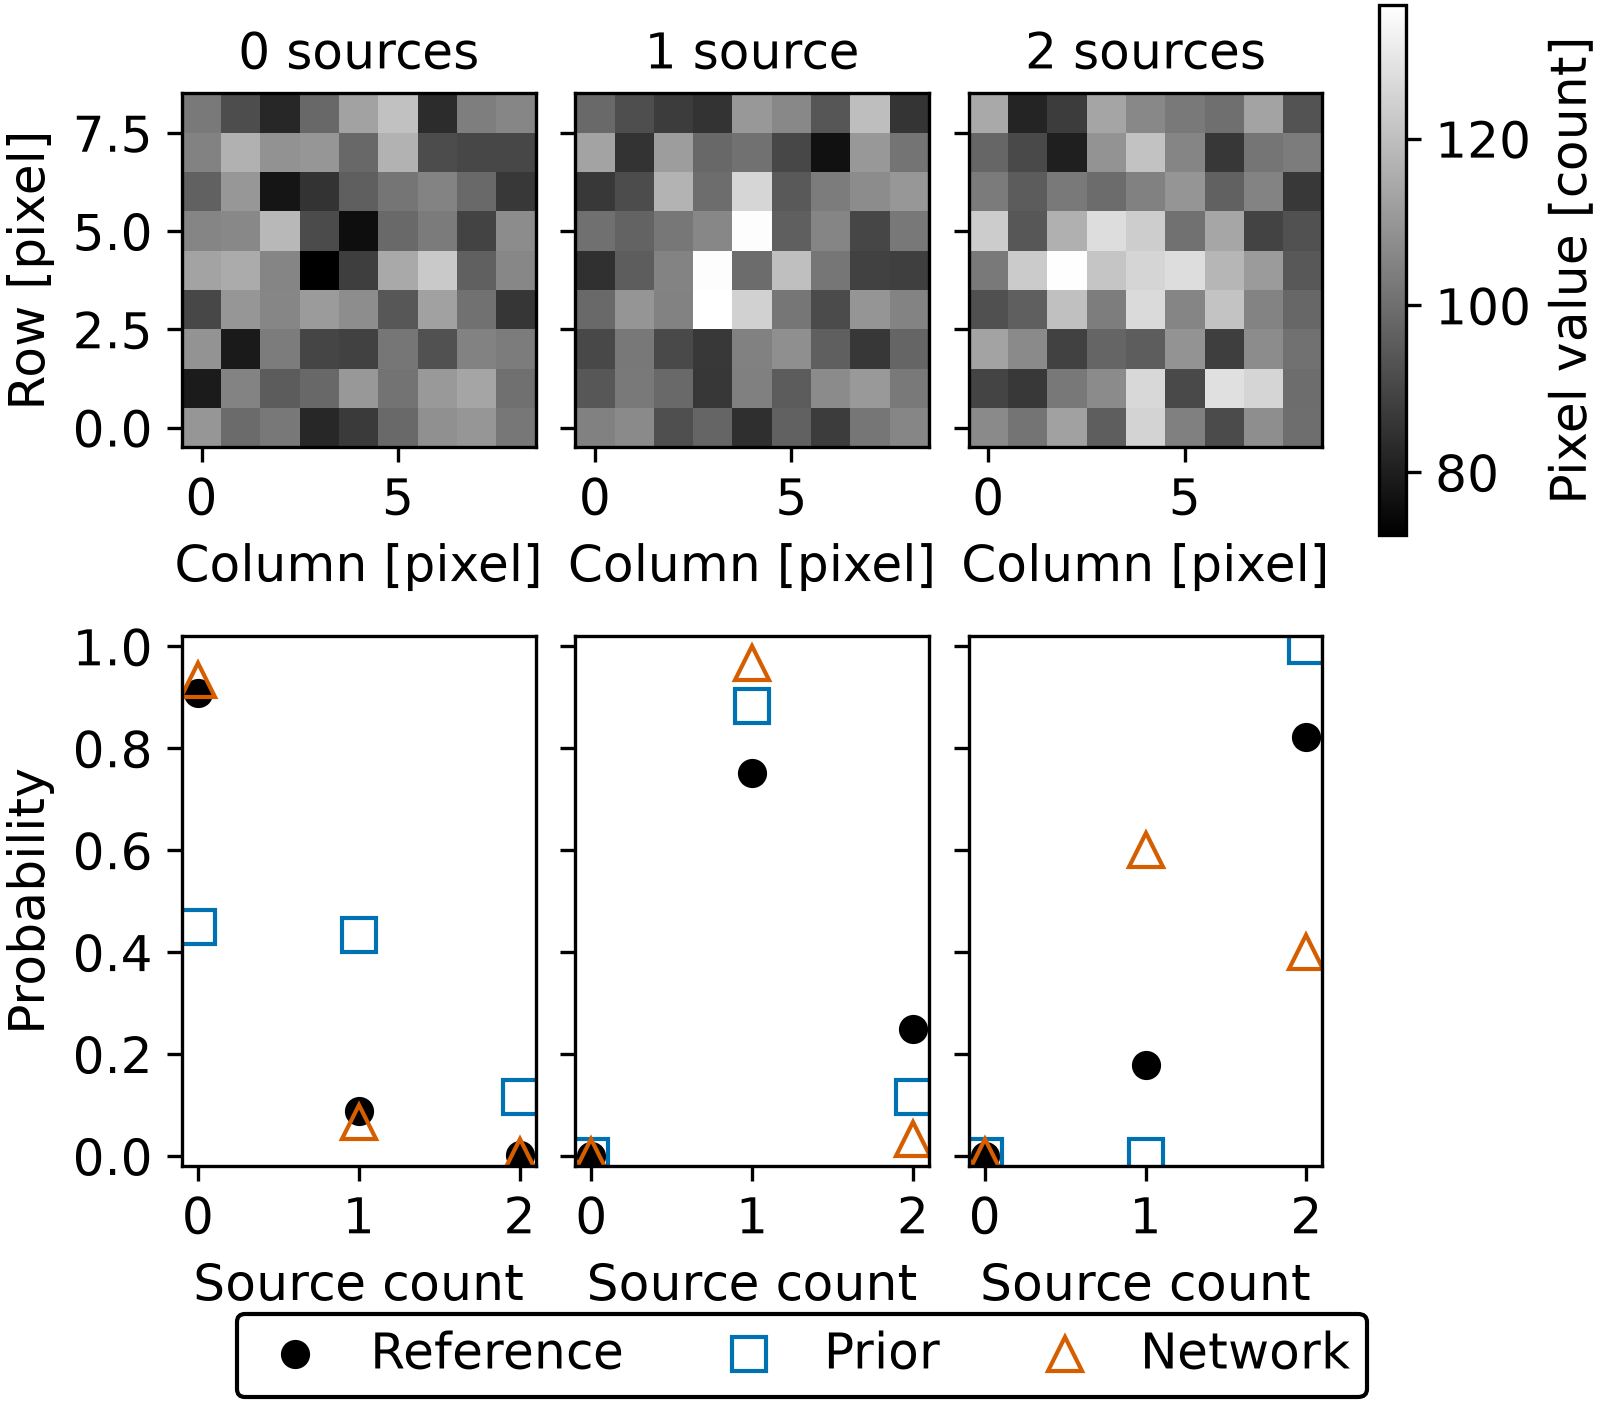

In [4]:
with redirect_stdout(StringIO()):
    display_example_visuals(
        "neural_proposal_efficiency",
        f"visuals/{run_id}_point_sources.png",
    )

## Flux uncertainties for two blended point sources

The second experiment fits the fluxes of two blurred point sources at known candidate positions in simulated images. Diffusion and mixture networks are compared with the same numerical image-likelihood reference. The shorter settings below check execution. The paper uses 20 test images and 2,000 samples per method.

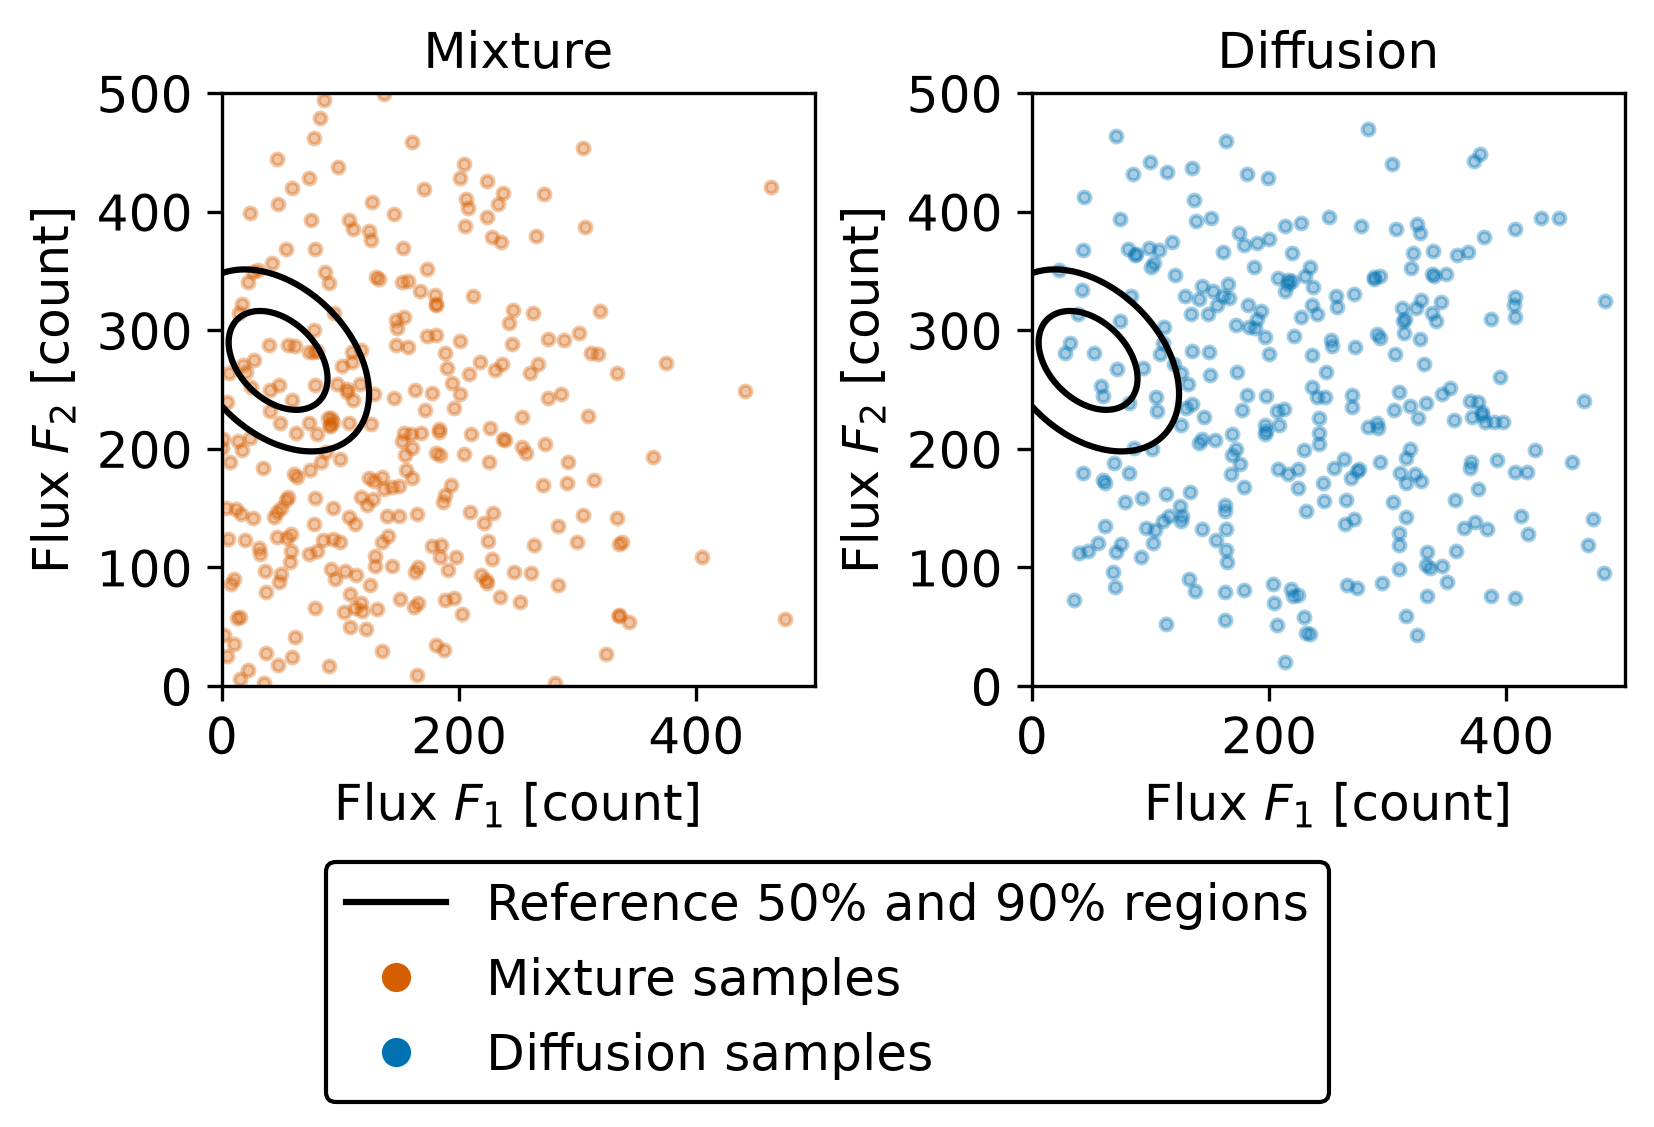

{'exact-grid': {'median_total_variation': 0.150205701879658,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.11692739397126697,
   0.1988484161233885],
  'marginal_90pct_coverage_successes': [3, 3],
  'marginal_90pct_coverage': [1.0, 1.0],
  'marginal_90pct_coverage_95pct_wilson_interval': [[0.43849391955098227, 1.0],
   [0.43849391955098227, 1.0]],
  'median_sampling_seconds': None},
 'mixture': {'median_total_variation': 0.8100237638115204,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.7767789197190049,
   0.8243876581947571],
  'marginal_90pct_coverage_successes': [3, 3],
  'marginal_90pct_coverage': [1.0, 1.0],
  'marginal_90pct_coverage_95pct_wilson_interval': [[0.43849391955098227, 1.0],
   [0.43849391955098227, 1.0]],
  'median_sampling_seconds': 0.06839408399901004},
 'diffusion': {'median_total_variation': 0.897104880375251,
  'median_total_variation_95pct_scene_bootstrap_interval': [0.8089516559394464,
   0.9575942550232267],
  'marginal_90pct_co

In [5]:
diffusion_run_id = f"diffusion_smoke_{uuid4().hex[:12]}"
with redirect_stdout(StringIO()):
    run_example_script(
        "neural_proposal_efficiency/neural_posterior_diffusion.py",
        "--run-id", diffusion_run_id,
        "--training-samples", "1024",
        "--validation-scenes", "3",
        "--posterior-draws", "300",
        "--diffusion-steps", "16",
        "--epochs", "8",
        "--mixture-components", "4",
    )
    diffusion_example = load_example_namespace(
        "neural_proposal_efficiency/neural_posterior_diffusion.py"
    )
diffusion_result_path = diffusion_example["RESULTS_PATH"] / f"{diffusion_run_id}_posterior.json"
print(f"Reading from {diffusion_result_path.name}...")
with diffusion_result_path.open(encoding="utf-8") as stream:
    diffusion_summary = json.load(stream)["summary"]
with redirect_stdout(StringIO()):
    display_example_visuals(
        "neural_proposal_efficiency",
        f"visuals/{diffusion_run_id}_posterior.png",
    )
diffusion_summary